In [1]:
!pip -q install scikit-learn matplotlib seaborn pillow

In [4]:
import os
import zipfile
import random
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 15

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# DATASET LOCATION: CHANGE THIS IF YOUR FOLDER NAME DIFFERS
DATASET_DIR = "/content/retina_dataset"

# Saved model and class labels
MODEL_PATH = "/content/eyeguard_efficientnet.keras"
LABELS_PATH = "/content/eyeguard_classes.json"

print("Dataset location:", DATASET_DIR)

TensorFlow: 2.21.0
GPU devices: []
Dataset location: /content/retina_dataset


In [5]:
from google.colab import files

uploaded = files.upload()

zip_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError(
        "Please upload your dataset as a .zip file."
    )

ZIP_PATH = "/content/" + zip_files[0]

os.makedirs(DATASET_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATASET_DIR)

# Find the folder that directly contains class folders.
root = Path(DATASET_DIR)

def image_files(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    return [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

def find_class_root(folder):
    candidates = [folder] + [
        p for p in folder.iterdir() if p.is_dir()
    ]

    for candidate in candidates:
        class_dirs = [
            p for p in candidate.iterdir()
            if p.is_dir() and image_files(p)
        ]

        if len(class_dirs) >= 2:
            return candidate

    raise ValueError(
        "Could not find at least two class folders. "
        "Organize the ZIP as class_name/image.jpg."
    )

root = find_class_root(root)

class_dirs = sorted([
    p for p in root.iterdir()
    if p.is_dir() and image_files(p)
])

class_names = [p.name for p in class_dirs]

if len(class_names) < 2:
    raise ValueError("At least two labelled classes are required.")

print("Dataset root:", root)
print("Detected classes:", class_names)

records = []

for label, class_dir in enumerate(class_dirs):
    valid_count = 0

    for path in image_files(class_dir):
        try:
            with Image.open(path) as img:
                img.verify()
            records.append((str(path), label))
            valid_count += 1
        except (UnidentifiedImageError, OSError, ValueError):
            print("Skipping invalid image:", path)

    print(f"{class_dir.name}: {valid_count} valid images")

counts = np.bincount(
    [label for _, label in records],
    minlength=len(class_names)
)

if len(records) == 0 or np.any(counts < 3):
    raise ValueError(
        "Each class needs at least 3 valid images for this "
        "train/validation/test split. More images are strongly "
        "recommended for meaningful evaluation."
    )

print("Total valid images:", len(records))

with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

Saving EyeGuard_Demo_Dataset.zip to EyeGuard_Demo_Dataset.zip
Dataset root: /content/retina_dataset
Detected classes: ['Cataract', 'Diabetic_Retinopathy', 'Glaucoma', 'Healthy']
Cataract: 25 valid images
Diabetic_Retinopathy: 25 valid images
Glaucoma: 25 valid images
Healthy: 25 valid images
Total valid images: 100


In [6]:
random.shuffle(records)

train_records, remaining = [], []
val_records, test_records = [], []

# Split within each class to keep every class represented.
for label in range(len(class_names)):
    group = [
        r for r in records if r[1] == label
    ]
    random.shuffle(group)

    n = len(group)

    if n < 3:
        raise ValueError(
            f"Class {class_names[label]} needs at least 3 images."
        )

    n_test = max(1, round(n * 0.15))
    n_val = max(1, round(n * 0.15))

    while n_test + n_val >= n:
        if n_val > 1:
            n_val -= 1
        elif n_test > 1:
            n_test -= 1
        else:
            raise ValueError("Not enough images for splitting.")

    test_records.extend(group[:n_test])
    val_records.extend(group[n_test:n_test + n_val])
    train_records.extend(group[n_test + n_val:])

random.shuffle(train_records)
random.shuffle(val_records)
random.shuffle(test_records)

print("Training images:", len(train_records))
print("Validation images:", len(val_records))
print("Test images:", len(test_records))

def decode_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(
        raw, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(items, training=False):
    paths = [r[0] for r in items]
    labels = [r[1] for r in items]

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(items), seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        augmentation = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.10),
        ])

        ds = ds.map(
            lambda x, y: (augmentation(x, training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_records, training=True)
val_ds = make_dataset(val_records)
test_ds = make_dataset(test_records)

print("Datasets are ready.")

Training images: 68
Validation images: 16
Test images: 16
Datasets are ready.


In [7]:
num_classes = len(class_names)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="retina_image"
)

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(
    256,
    activation="relu",
    name="feature_embedding"
)(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax",
    name="class_probabilities"
)(x)

model = models.Model(inputs, outputs, name="EyeGuardAI")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EyeGuardAI"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ retina_image (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_embedding (Dense)       │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [8]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("PHASE 1: Train the classification head")

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Fine-tune only the final portion of the pretrained backbone.
print("PHASE 2: Fine-tune the final layers")

base_model.trainable = True

for layer in base_model.layers[:-25]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

# Load the best checkpoint saved according to validation loss.
model = tf.keras.models.load_model(MODEL_PATH)

print("Saved model:", MODEL_PATH)
print("Saved class labels:", LABELS_PATH)

PHASE 1: Train the classification head
Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4999 - loss: 1.5527
Epoch 1: val_loss improved from None to 0.52439, saving model to /content/eyeguard_efficientnet.keras

Epoch 1: finished saving model to /content/eyeguard_efficientnet.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.5882 - loss: 1.1695 - val_accuracy: 0.7500 - val_loss: 0.5244 - learning_rate: 0.0010
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 795ms/step - accuracy: 0.8149 - loss: 0.3961
Epoch 2: val_loss improved from 0.52439 to 0.40375, saving model to /content/eyeguard_efficientnet.keras

Epoch 2: finished saving model to /content/eyeguard_efficientnet.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8088 - loss: 0.3749 - val_accuracy: 0.8750 - val_loss: 0.4037 - learning_rate: 0.0010
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 733ms/step - accuracy: 0.7571 - loss: 0.4797
Epoch 3: val_loss improved from 0.40375 to 0.37750, saving model to /content/eyeguard_ef

1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step - accuracy: 0.9375 - loss: 0.2781
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step

Test loss: 0.2781
Test accuracy: 0.9375

Classification report:
                      precision    recall  f1-score   support

            Cataract       1.00      1.00      1.00         4
Diabetic_Retinopathy       1.00      1.00      1.00         4
            Glaucoma       1.00      0.75      0.86         4
             Healthy       0.80      1.00      0.89         4

            accuracy                           0.94        16
           macro avg       0.95      0.94      0.94        16
        weighted avg       0.95      0.94      0.94        16

Macro precision: 0.95
Macro recall: 0.9375
Macro F1: 0.9365079365079365


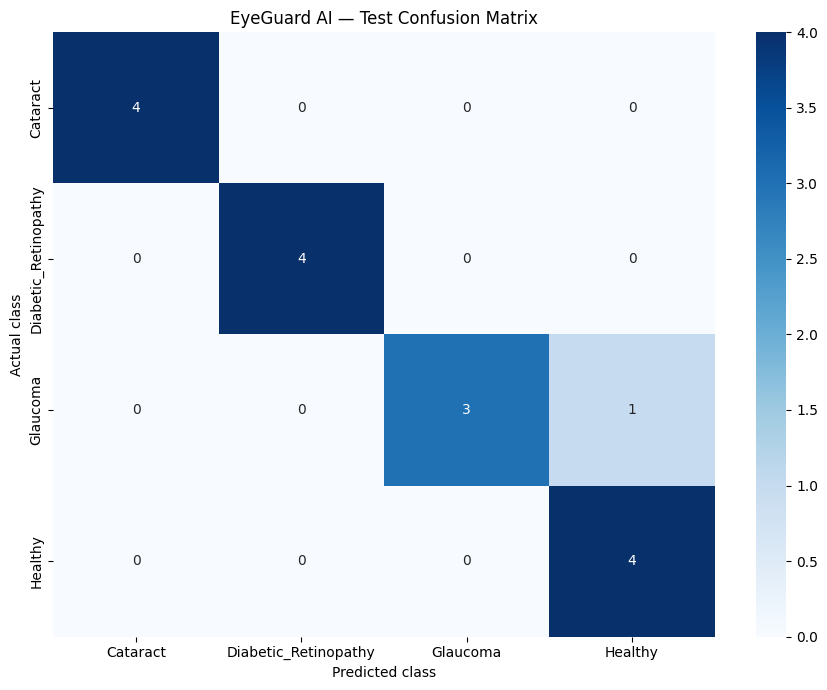

Macro ROC-AUC: 0.9844


In [9]:
test_loss, test_accuracy = model.evaluate(
    test_ds, verbose=1
)

y_true = np.concatenate([
    y.numpy() for _, y in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

print("Macro precision:", precision_score(
    y_true, y_pred, average="macro", zero_division=0
))
print("Macro recall:", recall_score(
    y_true, y_pred, average="macro", zero_division=0
))
print("Macro F1:", f1_score(
    y_true, y_pred, average="macro", zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("EyeGuard AI — Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Multiclass AUC is only meaningful when the test set
# contains examples of every class.
try:
    if len(np.unique(y_true)) == num_classes:
        y_true_onehot = tf.keras.utils.to_categorical(
            y_true, num_classes=num_classes
        )
        auc = roc_auc_score(
            y_true_onehot, y_prob,
            multi_class="ovr", average="macro"
        )
        print("Macro ROC-AUC:", round(float(auc), 4))
    else:
        print("ROC-AUC skipped: a class is missing in the test set.")
except ValueError as error:
    print("ROC-AUC unavailable:", error)

Upload one retinal image for prediction.


Saving WhatsApp Image 2026-09-25 at 21.13.58.jpeg to WhatsApp Image 2026-09-25 at 21.13.58.jpeg

Predicted class: Cataract
Model score: 55.55%

Class scores:
Cataract: 55.55%
Diabetic_Retinopathy: 25.20%
Healthy: 19.08%
Glaucoma: 0.17%


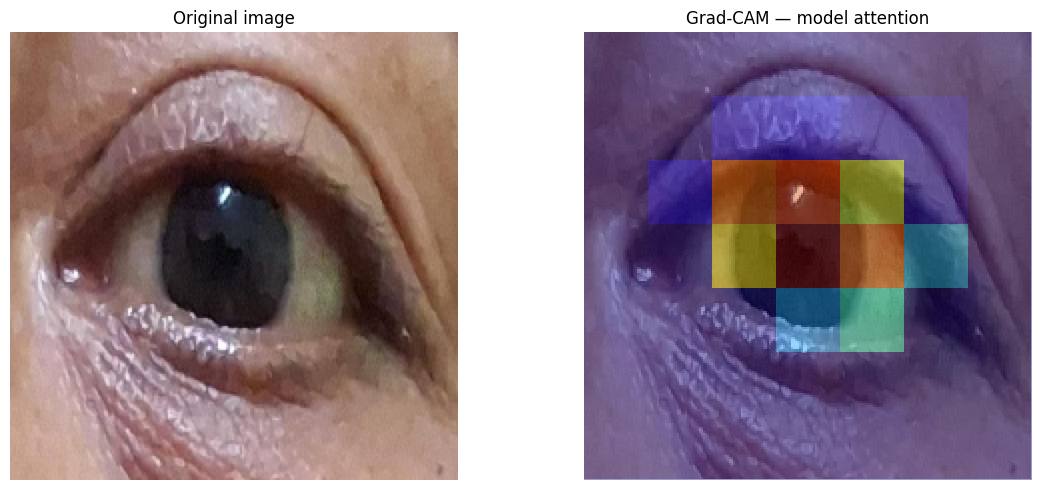

In [11]:
def load_one_image(path):
    img = tf.keras.utils.load_img(
        path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    arr = tf.keras.utils.img_to_array(img)
    return np.expand_dims(arr, axis=0), img

def make_gradcam(image_batch, class_index=None):
    # EfficientNet's final spatial feature map
    conv_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[
            base_model.get_layer("top_conv").output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_features = conv_model(
            image_batch, training=False
        )
        x = base_features

        # Pass features through the trained classification head.
        for layer in model.layers[2:]:
            x = layer(x, training=False)

        if class_index is None:
            class_index = tf.argmax(x[0])

        score = x[:, class_index]

    grads = tape.gradient(score, conv_outputs)

    if grads is None:
        raise RuntimeError("Grad-CAM gradients could not be calculated.")

    weights = tf.reduce_mean(grads, axis=(1, 2))
    heatmap = tf.reduce_sum(
        conv_outputs * weights[:, None, None, :],
        axis=-1
    )[0]

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.maximum(tf.reduce_max(heatmap), 1e-8)

    return heatmap.numpy()

from google.colab import files

print("Upload one retinal image for prediction.")
uploaded_image = files.upload()

image_paths = [
    name for name in uploaded_image
    if Path(name).suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

if not image_paths:
    raise ValueError("Please upload a valid image file.")

image_batch, original_image = load_one_image(image_paths[0])

probabilities = model.predict(image_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("\nPredicted class:", class_names[predicted_index])
print("Model score:", f"{probabilities[predicted_index] * 100:.2f}%")

print("\nClass scores:")
for name, score in sorted(
    zip(class_names, probabilities),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {score * 100:.2f}%")

heatmap = make_gradcam(image_batch, predicted_index)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(
    heatmap,
    cmap="jet",
    alpha=0.40,
    extent=(0, original_image.width, original_image.height, 0)
)
plt.title("Grad-CAM — model attention")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import json

model.save(MODEL_PATH)

with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print("Model saved:", MODEL_PATH)
print("Labels saved:", LABELS_PATH)

from google.colab import files
files.download(MODEL_PATH)
files.download(LABELS_PATH)

Model saved: /content/eyeguard_efficientnet.keras
Labels saved: /content/eyeguard_classes.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>